# 05 · P-values and confidence intervals

A p-value measures how extreme a specified statistic is relative to its null distribution. It is not the probability that a conclusion is wrong. A confidence interval describes uncertainty about an effect through a procedure with a specified long-run coverage rate. Use them alongside effect estimates and study design.

```mermaid
flowchart TD
    A[Specify null and statistic] --> B[Define more extreme]
    B --> C[Sum tail probabilities]
    C --> D[Interpret p without reversing the condition]
    D --> E[Estimate an effect and interval]
    E --> F[Check coverage and assumptions]
```

**Learning route:** tail probabilities → exact calculation → direction → interpretation → interval estimation. Prerequisites: Chapters [3](../03_Probability_Models/03_Probability_Models.md) and [4](../04_Hypothesis_Testing/04_Hypothesis_Testing.md).

## 1. Define the probability carefully

If larger $T$ is more extreme, a p-value is

$$p=P_{H_0}(T\ge T_{\mathrm{observed}}).$$

For a symmetric two-sided statistic centered at zero, we often use $P_{H_0}(|T|\ge|T_{\mathrm{observed}}|)$. The subscript means **calculated under the null model and its assumptions**, including the sampling or assignment mechanism. The statistic and extremeness rule must be specified to make this probability meaningful.

It includes results more extreme than the observed one because the procedure would regard them as at least as strong a discrepancy. Looking only at the probability of an exact observation misses that ordering. Exact continuous observations have probability zero even under perfectly reasonable models.

For a valid p-value, $P_{H_0}(p\le u)\le u$. In many continuous exact tests, equality holds and null p-values are uniform on $[0,1]$. Discrete tests are often conservative, with only a finite set of attainable p-values. A correctly calculated p-value is calibrated only under its model assumptions.

## 2. Work an exact example from beginning to end

A routing program is supposed to send each independent job to either of two identical servers with probability $q=0.5$. A preplanned audit of twelve jobs observes ten assigned to server A. We test $H_0:q=0.5$ against $H_1:q\ne0.5$.

Under $H_0$, $K\sim\operatorname{Binomial}(12,0.5)$. All $2^{12}=4096$ ordered assignment sequences have equal probability. The probability of **exactly** ten A assignments is

$$P(K=10)=\binom{12}{10}/4096=66/4096\approx0.01611.$$

But the two-sided p-value also includes 11 or 12 A assignments, and the equally extreme counts 0, 1, and 2:

$$p=\frac{1+12+66+66+12+1}{4096}
=\frac{158}{4096}\approx0.03857.$$

![The outcomes included in the exact two-sided p-value](figure/binomial_tails.png)

**Notebook setup.** Run all cells from top to bottom. Figures are saved in this chapter's `figure/` folder. Restart the kernel and run all after changing a simulation. See the repository README for installation.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# Works when Jupyter starts in either this chapter or the repository root.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "scripts" / "build_notebooks.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned course repository.")
FIGURE_DIR = ROOT / '05_P-Values_for_Confidence_Quantification' / "figure"
FIGURE_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (9, 4.8), "figure.dpi": 110,
    "font.size": 11, "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#087E8B", "#D55E00", "#7251A2", "#4477AA"]),
    "savefig.facecolor": "white", "axes.facecolor": "#FAFBFC",
})
TEAL, ORANGE, PURPLE = "#087E8B", "#D55E00", "#7251A2"

def save_figure(fig, name):
    """Save the exact figure used by Markdown and display it in the notebook."""
    fig.savefig(FIGURE_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    fig.savefig(FIGURE_DIR / f"{name}.svg", bbox_inches="tight")
    display(fig)
    plt.close(fig)

print("All datasets in this notebook are synthetic teaching examples.")


All datasets in this notebook are synthetic teaching examples.


Observed-count probability = 0.016113; two-sided p = 0.038574
One-sided p: 0.019287109375


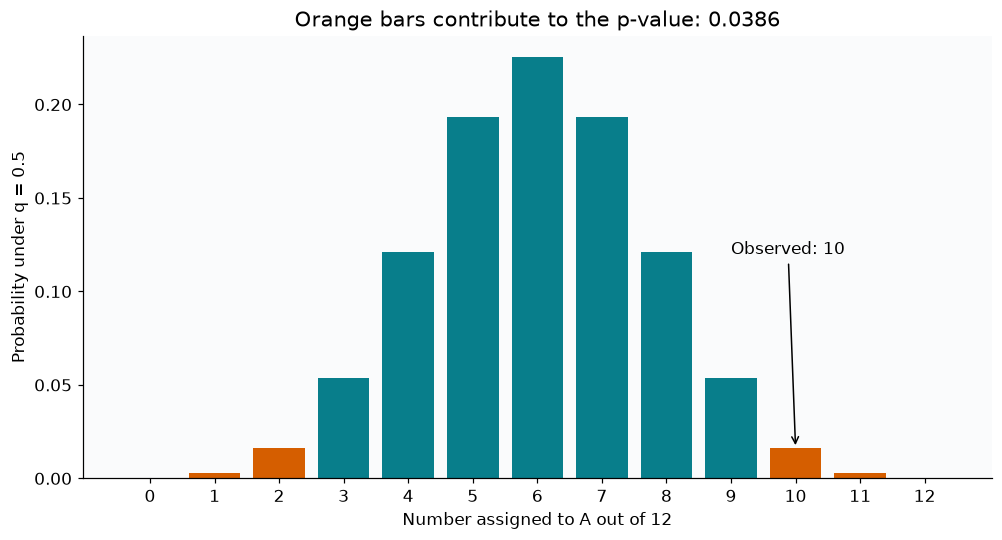

In [2]:
k = np.arange(13)
masses = stats.binom.pmf(k,12,.5)
extreme = (k<=2)|(k>=10)
p_manual = masses[extreme].sum()
result = stats.binomtest(10,12,p=.5,alternative="two-sided")
assert np.isclose(p_manual,158/4096) and np.isclose(p_manual,result.pvalue)
print(f"Observed-count probability = {masses[10]:.6f}; two-sided p = {p_manual:.6f}")
print("One-sided p:",stats.binomtest(10,12,p=.5,alternative="greater").pvalue)
fig, ax = plt.subplots(layout="constrained")
ax.bar(k,masses,color=np.where(extreme,ORANGE,TEAL))
ax.set(xlabel="Number assigned to A out of 12",ylabel="Probability under q = 0.5",
       xticks=k,title=f"Orange bars contribute to the p-value: {p_manual:.4f}")
ax.annotate("Observed: 10",xy=(10,masses[10]),xytext=(9,.12),arrowprops={"arrowstyle":"->"})
save_figure(fig,"binomial_tails")

At a preselected $\alpha=0.05$, reject $H_0$. A precise report is: “Ten of twelve jobs went to A; under independent 50:50 routing, the exact two-sided p-value is 0.0386.” This result is unusual under the model. It does not establish that $q=10/12$ exactly or that the result has a 3.86% chance of being a false positive.

The calculation assumes independent assignments. Sticky sessions, batching, or a deliberate balancing schedule would change the relevant null distribution. A small p-value could expose a misspecified independence model as well as an unequal routing probability.

## 3. One-sided and two-sided tests ask different questions

For the preplanned alternative $q>0.5$, the p-value would be $P(K\ge10)=79/4096\approx0.01929$. It happens to be half the two-sided value because this null is symmetric and the observed count is in the upper tail.

That shortcut is not universal. For discrete asymmetric distributions there are different legitimate two-sided orderings. SciPy's exact binomial two-sided test adds masses no larger than the observed mass, with numerical tolerance. State the method instead of automatically doubling a tail.

A fixed one-sided test can control its Type I error. The problem is choosing the favorable direction after observing the data. In the continuous normal case, selecting the smaller of the two one-sided p-values and testing at 0.05 rejects approximately 10% of true nulls. The notebook demonstrates all three procedures on the **same** null draws.

![Calibration of fixed and data-chosen directions](figure/direction_selection.png)

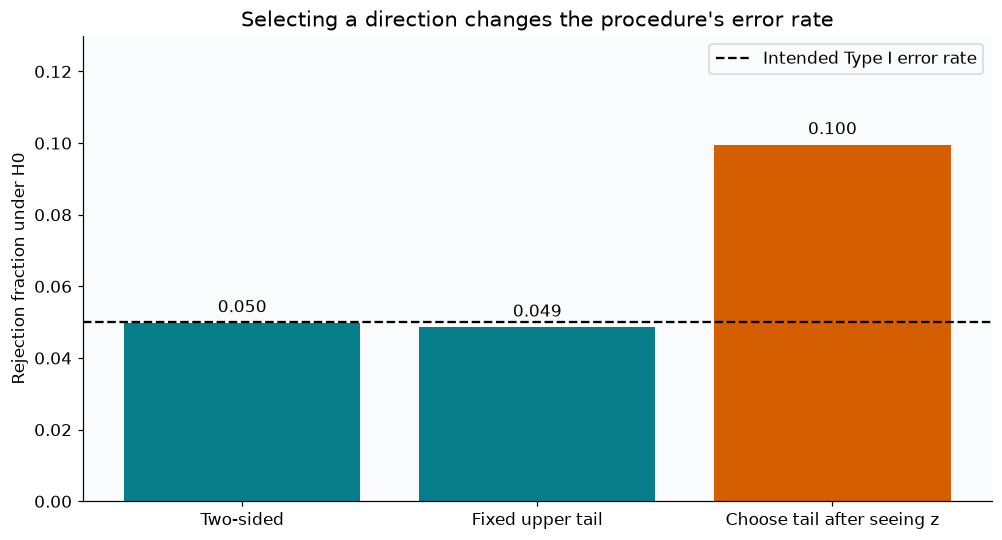

In [3]:
rng = np.random.default_rng(505)
z = rng.standard_normal(100000)
p_two = 2*stats.norm.sf(np.abs(z))
p_fixed = stats.norm.sf(z)
p_selected = np.minimum(stats.norm.cdf(z),stats.norm.sf(z))
rates = [np.mean(p<=.05) for p in [p_two,p_fixed,p_selected]]
fig, ax = plt.subplots(layout="constrained")
ax.bar(["Two-sided", "Fixed upper tail", "Choose tail after seeing z"],rates,color=[TEAL,TEAL,ORANGE])
ax.axhline(.05,color="black",ls="--",label="Intended Type I error rate")
ax.set(ylabel="Rejection fraction under H0",ylim=(0,.13),title="Selecting a direction changes the procedure's error rate")
for i,r in enumerate(rates): ax.text(i,r+.003,f"{r:.3f}",ha="center")
ax.legend()
save_figure(fig,"direction_selection")

## 4. What a p-value cannot tell you

| Incorrect statement | More accurate interpretation |
|---|---|
| “$p=0.04$ means the null is 4% likely.” | The probability was calculated assuming the null; it does not assign the null a posterior probability. |
| “There is a 96% chance the finding will replicate.” | Replication depends on the true effect, precision, design, and analysis. |
| “A smaller p-value means a larger effect.” | Sample size and variability affect the p-value as well as the estimated effect. |
| “$p>0.05$ proves no difference.” | The data may be imprecise; examine which effects remain compatible with the interval. |
| “$p=0.049$ and $p=0.051$ give opposite scientific truths.” | A decision threshold is a rule; the evidence changes gradually. |

This distinction matters despite the historical folder name “confidence quantification.” Here we use **confidence** in its formal interval-procedure sense, and **p-value** for null-model compatibility, not as $1-p$ certainty in a claim.

## 5. Confidence intervals describe a procedure's coverage

A 95% confidence-interval procedure includes the fixed true parameter in 95% of repeated samples under its assumptions. For one realized frequentist interval, the endpoints are now fixed and the parameter either lies inside or outside. The coverage statement does not assign a 95% posterior probability to that fixed interval.

For iid normal observations with unknown SD, a two-sided interval for the mean is

$$\bar x\pm t_{1-\alpha/2,n-1}\frac{s}{\sqrt n}.$$

The center is the estimate, $s/\sqrt n$ is its estimated standard error, and the t critical value accounts for estimating SD. The t distribution is developed in Chapter 8. For now, software can provide its quantile.

Five invented machine setup times are 18, 20, 22, 24, and 26 minutes. Their mean is 22, sample SD is $\sqrt{10}$, and estimated SE is $\sqrt2$. With four degrees of freedom, $t_{0.975,4}\approx2.776$, giving

$$22\pm2.776\sqrt2\approx[18.074,25.926]\text{ minutes}.$$

This interval concerns the **population mean**, not 95% of individual setup times. A prediction interval for one future observation must include individual variability too.

In [4]:
setup_times = np.array([18,20,22,24,26],dtype=float)
se = stats.sem(setup_times)
critical = stats.t.ppf(.975,len(setup_times)-1)
ci = setup_times.mean()+np.array([-1,1])*critical*se
test = stats.ttest_1samp(setup_times,popmean=20)
print("Mean:",setup_times.mean(),"SE:",se,"95% CI:",ci)
print(f"Test of mean=20: t={test.statistic:.4f}, p={test.pvalue:.4f}")
assert ci[0]<20<ci[1] and test.pvalue>.05

Mean: 22.0 SE: 1.4142135623730951 95% CI: [18.07351368 25.92648632]
Test of mean=20: t=1.4142, p=0.2302


For the same two-sided t-test and the same assumptions, a 95% confidence interval excludes a hypothesized mean exactly when the two-sided test rejects it at 0.05, apart from boundary conventions. Here 20 is inside the interval, and the t-test of $\mu=20$ does not reject. This test–interval correspondence is not a license to mix different models or one-sided and two-sided procedures.

## 6. See coverage instead of memorizing it

The notebook repeatedly samples twelve observations from a normal population with known mean 50, but estimates SD separately in each sample. Each interval uses its own mean and SD. The simulation knows the truth, so it can mark misses. In real analysis we cannot color our interval by whether it covers an unknown parameter.

![Repeated t confidence intervals and the fixed true mean](figure/interval_coverage.png)

Coverage across 10000 samples: 0.9539; Monte Carlo SE 0.0021


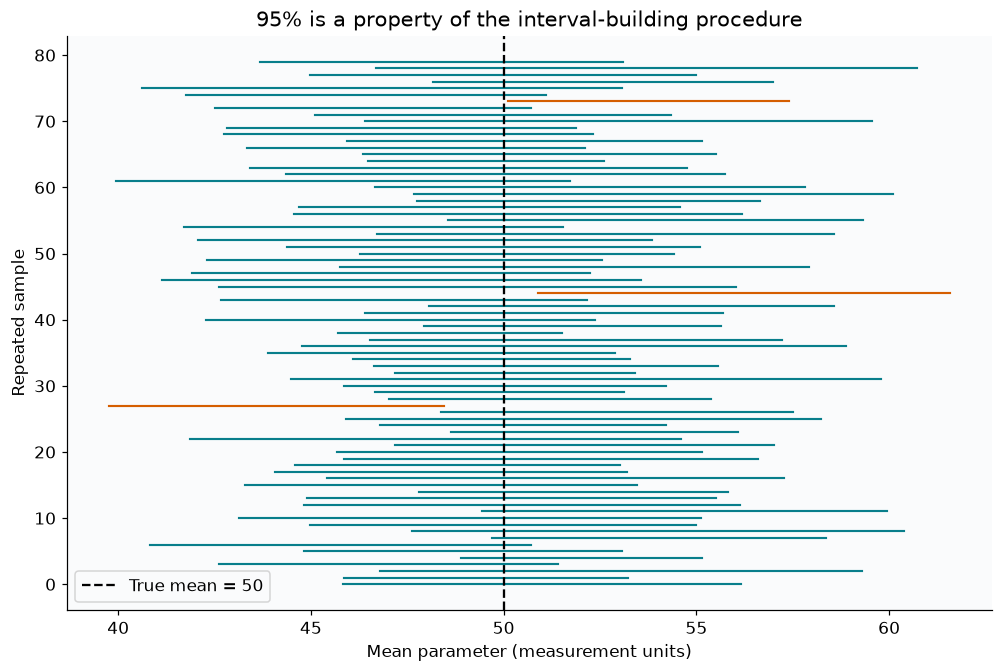

In [5]:
rng = np.random.default_rng(506)
true_mean, n, repetitions = 50, 12, 10000
samples = rng.normal(true_mean,8,(repetitions,n))
means = samples.mean(axis=1)
margin = stats.t.ppf(.975,n-1)*samples.std(axis=1,ddof=1)/np.sqrt(n)
low, high = means-margin,means+margin
covers = (low<=true_mean)&(high>=true_mean)
coverage = covers.mean()
print(f"Coverage across {repetitions} samples: {coverage:.4f}; Monte Carlo SE {np.sqrt(coverage*(1-coverage)/repetitions):.4f}")
fig, ax = plt.subplots(figsize=(9,6),layout="constrained")
for i in range(80):
    ax.plot([low[i],high[i]],[i,i],color=TEAL if covers[i] else ORANGE,lw=1.4)
ax.axvline(true_mean,color="black",ls="--",label="True mean = 50")
ax.set(xlabel="Mean parameter (measurement units)",ylabel="Repeated sample",
       title="95% is a property of the interval-building procedure")
ax.legend()
save_figure(fig,"interval_coverage")

The displayed eighty intervals illustrate variability; their coverage need not be exactly 95%. A larger Monte Carlo experiment estimates the long-run coverage more precisely. Approximate Monte Carlo SE for a simulated proportion $\hat c$ from $B$ independent repetitions is $\sqrt{\hat c(1-\hat c)/B}$. This is simulation uncertainty, distinct from uncertainty in a particular dataset's mean.

## 7. Practice

1. In eight independent 50:50 assignments, all eight go to A. Compute the exact two-sided p-value.
2. In the twelve-job audit above, what is the true-null rejection probability of the exact two-sided test at $\alpha=0.05$? Why is it not exactly 0.05?
3. A known-SD normal mean estimate is 40 with SE 2. Find an approximate 95% interval. What happens if sample size quadruples with the same SD?
4. Can a narrow interval around a practically negligible effect coexist with a tiny p-value for zero effect?
5. Rewrite: “The p-value is 0.8, so there is an 80% probability that the methods are equal.”

## 8. Worked answers

1. Include all A and all B: $2/2^8=0.0078125$.
2. Rejection occurs at $K\le2$ or $K\ge10$, so its probability is $158/4096\approx0.038574$. The discrete distribution cannot use exactly 5% of its probability mass with this ordinary nonrandomized rule.
3. $40\pm1.96(2)=[36.08,43.92]$. Quadrupling independent sample size halves the SE to 1, making the margin 1.96 if the observed center stays 40.
4. Yes. High precision can distinguish a very small nonzero effect from zero. Whether that effect matters requires a practical scale.
5. “The observed statistic is not unusual under the specified equal-means null model. This does not establish equality; we also need the estimated difference and its uncertainty.”

In [6]:
all_p = np.array([stats.binomtest(int(i),12,.5).pvalue for i in range(13)])
exact_size = stats.binom.pmf(np.arange(13),12,.5)[all_p<=.05].sum()
assert np.isclose(exact_size,158/4096)
assert np.isclose(stats.binomtest(8,8,.5).pvalue,2/256)
print("Exact size for n=12:",exact_size)
print("Known-SD approximate interval:",40+np.array([-1,1])*1.96*2)

Exact size for n=12: 0.038574218750000014
Known-SD approximate interval: [36.08 43.92]


## References and next step

Reading connection: Starmer (2026), Chapter 5, [SQ](../Reference.md#sq-statquest). Interpretations follow the principles in [the ASA statement](https://www.amstat.org/asa/files/pdfs/p-valuestatement.pdf). Formulas: [NIST mean confidence limits](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm). Exact-test convention: [SciPy binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html).

Next: [06 · Linear regression](../06_Linear_Regression/06_Linear_Regression.md).